In [1]:
import xarray as xr
import numpy as np
import cftime
import xesmf as xe
import TCs
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy import stats
from scipy.signal import cheby1, filtfilt
import pandas as pd
import matplotlib as mpl

import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
from cartopy.crs import PlateCarree, Robinson
from matplotlib.ticker import ScalarFormatter
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D

import dask
dask.config.set({'array.slicing.split_large_chunks': True})
from scipy import stats

import json
import Plot

In [2]:
def lat_formatter(x, pos):
    hemi = 'N' if x > 0 else 'S' if x < 0 else ''
    return f"{abs(int(x))}°{hemi}"

def lon_formatter(x, pos):
    if x < 180:
        return f"{int(x)}°E"
    elif x == 180:
        return f"{int(x)}°"
    else:
        return f"{int(360-x)}°W"

In [3]:
ds = xr.open_dataset("FigureS2.nc")

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


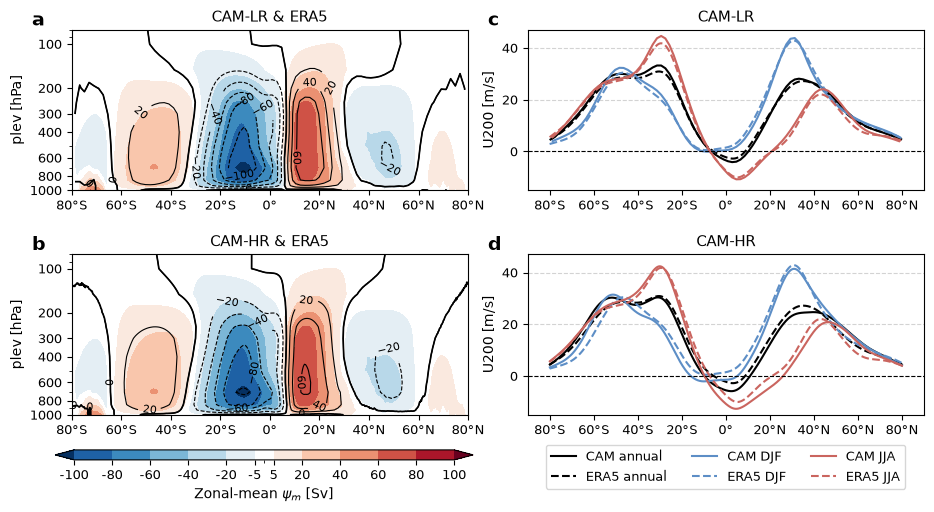

In [8]:
fig, axs = plt.subplots(ncols=2, nrows=2, figsize=(11,5))
plt.subplots_adjust(hspace=0.4, wspace=0.15)
lat_range = slice(-80, 80)
ratio = 100
numbers = [['a', 'c'], ['b', 'd']]
titles = [['CAM-LR & ERA5', 'CAM-LR'], ['CAM-HR & ERA5', 'CAM-HR'], ]
cmap1, levels1, norm1 = Plot.def_colormap(max=100, white=5, interval=20, cmap='RdBu_r')
cmap2, levels2, norm2 = Plot.def_colormap(max=80, white=5, interval=20, cmap='RdBu_r')

# Column 1: historical overtunning circulation
for irow, res in enumerate(['sdcam', 'hicam']):
    cf = axs[irow][0].contourf(ds.psi_era5_hist.lat_era5, ds.psi_era5_hist.plev_era5, ds.psi_era5_hist, 
                               cmap=cmap1, levels=levels1, norm=norm1, extend='both')
    cc = axs[irow][0].contour(ds[f'psi_{res}_hist'][f'lat_{res}'], ds[f'psi_{res}_hist'][f'plev_{res}'], ds[f'psi_{res}_hist'], 
                              levels=np.arange(-200, 200+20, 20), colors='black', linewidths=0.8)
    axs[irow][0].contour(ds[f'psi_{res}_hist'][f'lat_{res}'], ds[f'psi_{res}_hist'][f'plev_{res}'], ds[f'psi_{res}_hist'], 
                          levels=[0], colors='black', linewidths=1.2)
    axs[irow][0].clabel(cc, inline=True, fontsize=8)
    axs[irow][0].set_title(titles[irow][0], fontsize=11)
    axs[irow][0].annotate(
        numbers[irow][0], xy=(-0.1, 1.12), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top'
    )

# Column 2: historical Walker circulation
for irow,res in enumerate(['sdcam', 'hicam']):
    U200_cam = ds[f'U200_{res}_season']
    U200_era5 = ds.U200_era5_season
    U200_cam.mean('season').plot(ax=axs[irow][1], color='k', linestyle='solid', label=f'CAM annual')
    U200_era5.mean('season').plot(ax=axs[irow][1], color='k', linestyle='dashed', label=f'ERA5 annual')
    for iseason,icolor in zip(['DJF', 'JJA'], ['#5D8EC6', '#CA655F']):
        U200_cam.sel(season=iseason).plot(ax=axs[irow][1], color=icolor, linestyle='solid', label=f'CAM {iseason}')
        U200_era5.sel(season=iseason).plot(ax=axs[irow][1], color=icolor, linestyle='dashed', label=f'ERA5 {iseason}')
    axs[irow][1].set_title(titles[irow][1], fontsize=11)
    axs[irow][1].annotate(
        numbers[irow][1], xy=(-0.1, 1.12), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top'
    )
    
for ax in axs[:,0]:
    ax.invert_yaxis()
    ax.set_yscale('log')
    ax.set_ylim(1000, 80)
    ax.tick_params(labelsize=9)
    ax.set_yticks([100, 200, 300, 400, 600, 800, 1000])
    ax.get_yaxis().set_major_formatter(ScalarFormatter())
    ax.set_ylabel('plev [hPa]')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lat_formatter))
for ax in axs[:,1]:
    ax.grid(axis='y', linewidth=0.8, color='lightgrey', linestyle='dashed')
    ax.axhline(0, linewidth=0.8, linestyle='dashed', color='k')
    ax.set_xlabel('')
    ax.set_ylim(-15, 47)
    ax.set_xlim(-90, 90)
    ax.tick_params(labelsize=9)
    ax.set_ylabel('U200 [m/s]')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lat_formatter))

handles, labels = axs[1][1].get_legend_handles_labels()
leg = axs[1][1].legend(
    handles, labels, ncol=3,
    loc='lower left', bbox_to_anchor=(0.03, -0.5), fontsize=9, frameon=True
)

cax = fig.add_axes([0.11, 0.02, 0.38, 0.02])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap1, norm=norm1), 
                    cax=cax, orientation='horizontal', ticks=levels1[levels1 != 0], extend='both', spacing='proportional', 
                    label=r'Zonal-mean $\psi_m$ [Sv]')

major_ticks = [-100, -80, -60, -40, -20, -5, 5, 20, 40, 60, 80, 100]
major_labels = [
    '' if t not in major_ticks else f'{t:g}'
    for t in levels1[levels1 != 0]
]
cbar.ax.set_xticklabels(major_labels);
cbar.ax.tick_params(labelsize=9)

# plt.savefig(f'FigureS2.png', bbox_inches='tight', dpi=300)